In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
df = pd.read_csv("smartcart_customers.csv")

In [61]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [62]:
df.shape

(2240, 22)

In [63]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Preprocessing

## 1.Handling missing values

In [64]:
from sklearn.impute import SimpleImputer
import numpy as np
df["Income"] = df["Income"].fillna(np.nan)
imp_median = SimpleImputer(strategy = "median")
df[["Income"]] = imp_median.fit_transform(df[["Income"]])

## Feature Engineering

In [65]:
df.columns

Index(['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome',
       'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits',
       'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts',
       'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases',
       'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth',
       'Complain', 'Response'],
      dtype='object')

In [66]:
df[["Year_Birth", "Dt_Customer"]]

,Year_Birth,Dt_Customer
0,1957,04-09-2012
1,1954,08-03-2014
2,1965,21-08-2013
3,1984,10-02-2014
4,1981,19-01-2014
...,...,...
2235,1967,13-06-2013
2236,1946,10-06-2014
2237,1981,25-01-2014
2238,1956,24-01-2014


In [67]:
#converting year birth into age
df["Age"] = 2026 - df["Year_Birth"]

In [68]:
df["Age"]

0       69
1       72
2       61
3       42
4       45
        ..
2235    59
2236    80
2237    45
2238    70
2239    72
Name: Age, Length: 2240, dtype: int64

In [69]:
#converting date-time data into meaningful data which is joining date 
df["Dt_Customer"] = pd.to_datetime(df['Dt_Customer'], dayfirst = True)
ref_date = df['Dt_Customer'].max()

print(ref_date)

2014-06-29 00:00:00


In [70]:
df['Customer_tenure_date'] = (ref_date - df['Dt_Customer']).dt.days
##here Customer_tenure_date is represent no. of days spent from the joining date

In [71]:
# Now we create two new features which represents total spending of customer which is combination of following features
# (MntWines, MntFishProducts, MntMeatProducts, MntFruits, MntGoldProds, MntSweetProducts) and no. of children which is 
#combination of following features (Teenhome, Kidhome)

#total spending
df["Total_spending"] = (df["MntWines"] + df["MntFishProducts"] + df["MntMeatProducts"] + df["MntFruits"] + df["MntGoldProds"] + df["MntSweetProducts"])

#Total_children
df["Total_children"] = df["Teenhome"] + df["Kidhome"]

In [72]:
df["Education"].value_counts()

Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

In [73]:
#Let's convernt categorical data into meaning ful data

#Education
df["Education"] = df["Education"].map({
    "Graduation" : "Graduate",
    "2n Cycle" : "Undergraduate", 
    "Basic" : "Undergraduate", 
    "Master" : "Postgraduate", 
    "PhD" : "Postgraduate"})

In [74]:
df["Education"].value_counts()

Education
Graduate         1127
Postgraduate      856
Undergraduate     257
Name: count, dtype: int64

In [75]:
#Marital_Status
df["Marital_Status"].value_counts()

Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64

In [76]:
df["Living_with"] = df["Marital_Status"].map({
    "Married" : "Partner", 
    "Together" : "Partner", 
    "Single" : "Alone", 
    "Divorced" : "Alone", 
    "Widow" : "Alone", 
    "Absurd" : "Alone", 
    "YOLO" : "Alone"})

In [78]:
df["Living_with"].value_counts()

Living_with
Partner    1444
Alone       793
Name: count, dtype: int64

## Drop Columns

In [79]:
cols = ["ID", "Kidhome", "Teenhome", "Dt_Customer", "Year_Birth", "Marital_Status"]
spending_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]

cols_to_drop = cols + spending_cols

df_cleaned = df.drop(columns = cols_to_drop)

In [82]:
print(df_cleaned.shape)
df.shape

(2240, 15)


(2240, 27)

## Outliers

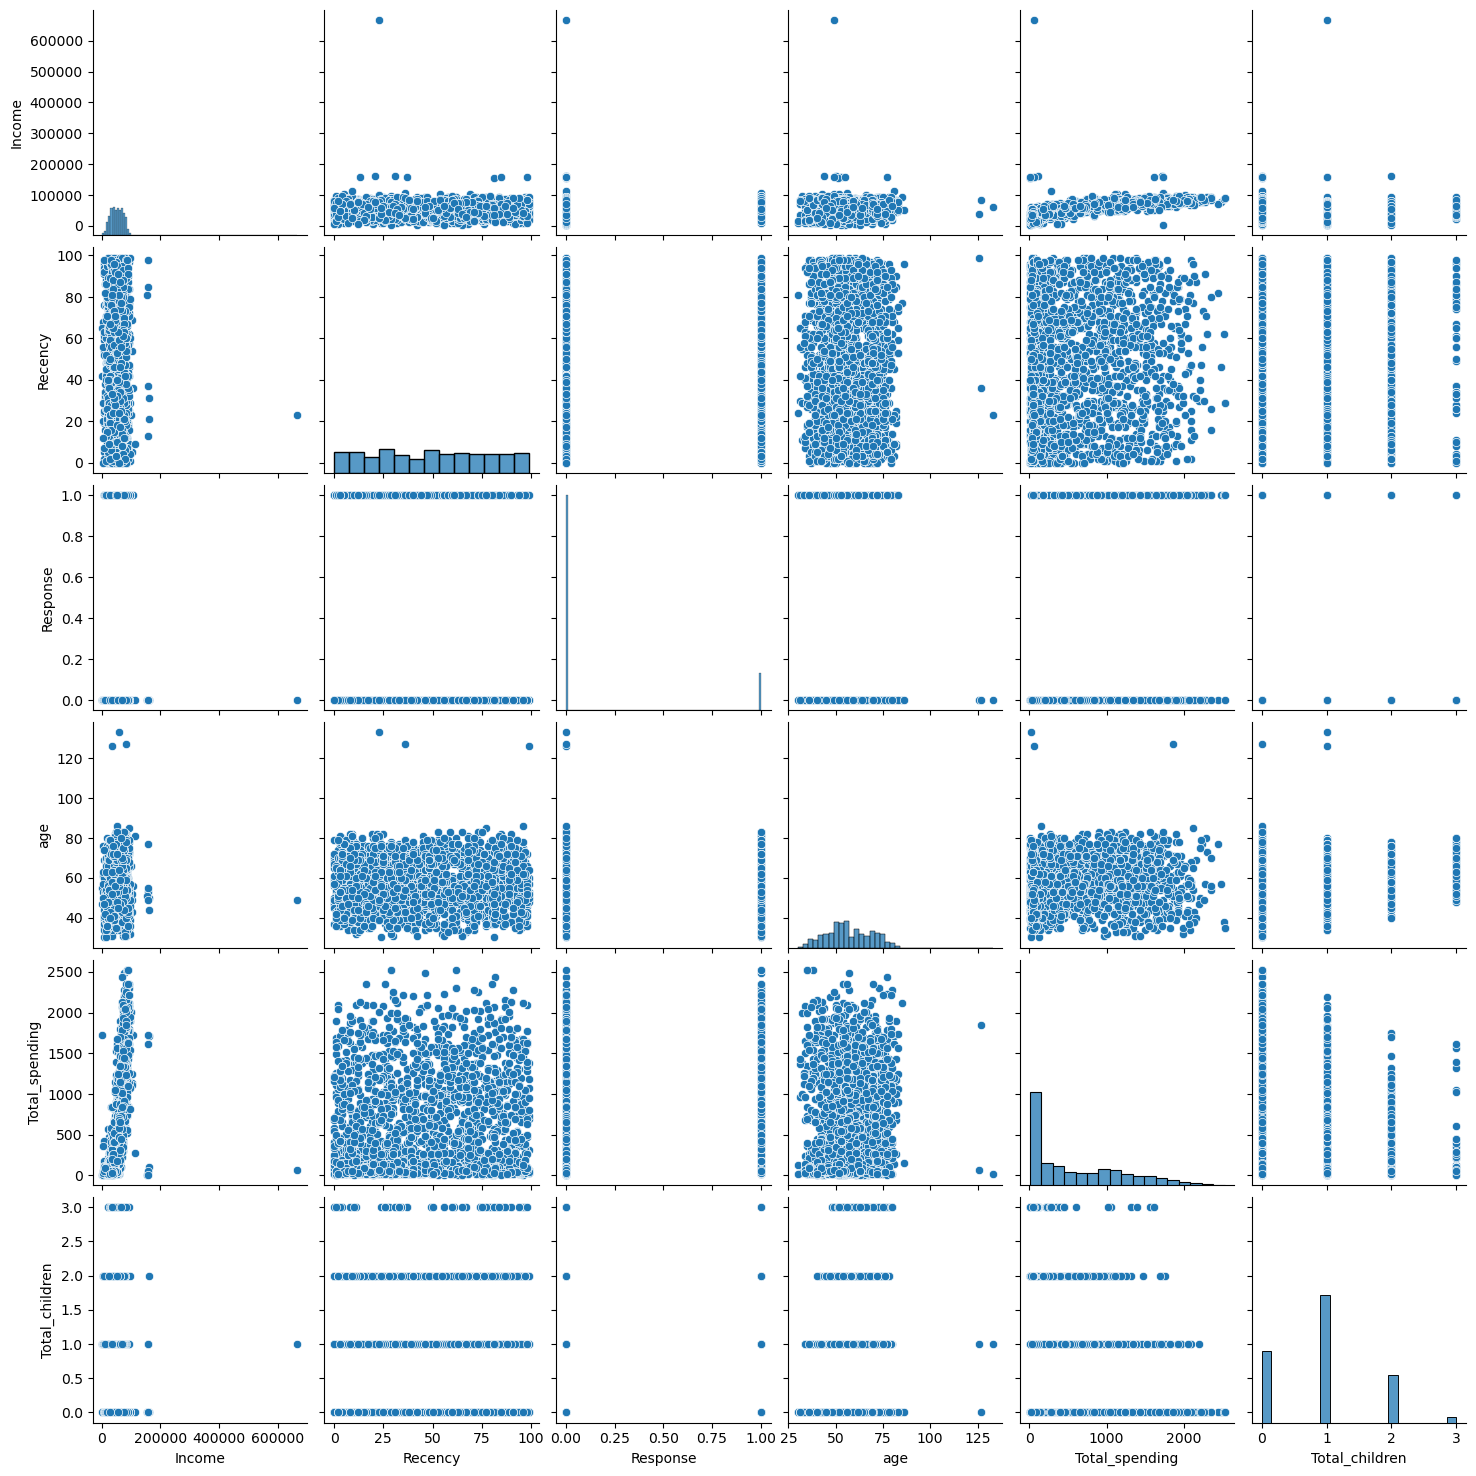

In [23]:
# Looking out outliers by ploting graph

cols = ["Income", "Recency", "Response", "age", "Total_spending", "Total_children"]

sns.pairplot(df_cleaned[cols])
#pair plot is basically scatter plot of multiple features with each other

In [89]:
#Remove outlier
print("Data size with outliers", len(df_cleaned))
df_cleaned = df_cleaned[df_cleaned["Age"] < 90]
df_cleaned = df_cleaned[df_cleaned["Income"] < 600_000]
print("Data size without outliers", len(df_cleaned))

Data size with outliers 2236
Data size without outliers 2236


## Heatmap

<Axes: >

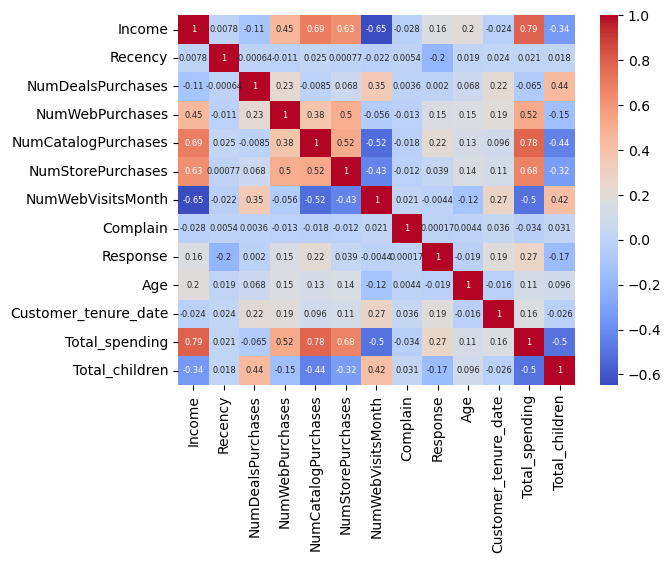

In [90]:
corr = df_cleaned.corr(numeric_only = True)
sns.heatmap(
    corr, 
    annot = True,
    annot_kws = {"size": 6},
    cmap = "coolwarm"
)

## Encoding

In [91]:
from sklearn.preprocessing import OneHotEncoder

In [93]:
## note here:- we didn't use drop_first = true bcz, in unsupervised learning we not use drop first to perform encoding
ohe = OneHotEncoder()

cat_cols = ["Education", "Living_with"]
enc_cols = ohe.fit_transform(df_cleaned[cat_cols])

In [95]:
enc_df = pd.DataFrame(enc_cols.toarray(), columns = ohe.get_feature_names_out(cat_cols), index = df_cleaned.index)

In [97]:
df_encoded = pd.concat([df_cleaned.drop(columns = cat_cols), enc_df], axis = 1)

In [100]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_tenure_date,Total_spending,Total_children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_with_Alone,Living_with_Partner,Living_with_nan
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,0.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0.0


## Scaling

In [101]:
from sklearn.preprocessing import StandardScaler

In [103]:
X = df_encoded

In [104]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## 2D Visualization

In [105]:
X_scaled.shape

(2236, 19)

In [106]:
#2D
from sklearn.decomposition import PCA

pca = PCA(n_components = 2)
X_pca_2d = pca.fit_transform(X_scaled)

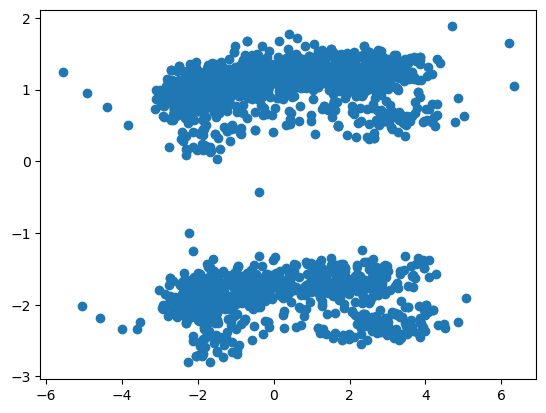

In [107]:
#plot

plt.scatter(
    x = X_pca[:, 0],
    y = X_pca[:, 1]
)

In [109]:
pca.explained_variance_ratio_

array([0.21948072, 0.10772484])

## 3D Visualization

In [115]:
pca2 = PCA(n_components = 3)
X_pca_3d = pca2.fit_transform(X_scaled)

Text(0.5, 0.92, '3D Projection')

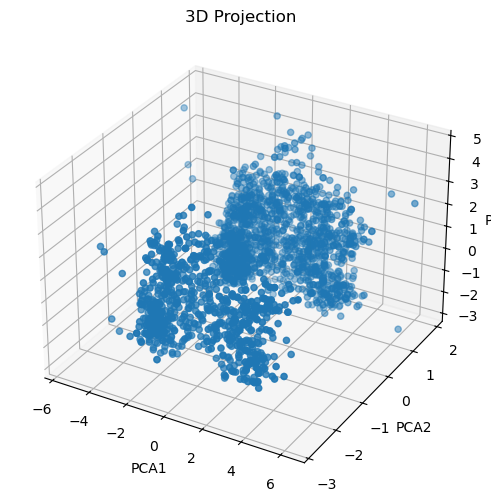

In [168]:
# plot
fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2])

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D Projection")

## Analyze K value

### 1.Elbow Method

In [ ]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    kmeans.fit_transform(X_pca_3d)
    wcss.append(kmeans.inertia_)

In [127]:
knee = KneeLocator(range(1, 11), wcss, curve = "convex", direction = "decreasing")
print(knee.elbow)

3


Text(0.5, 1.0, 'k v\\s wcss')

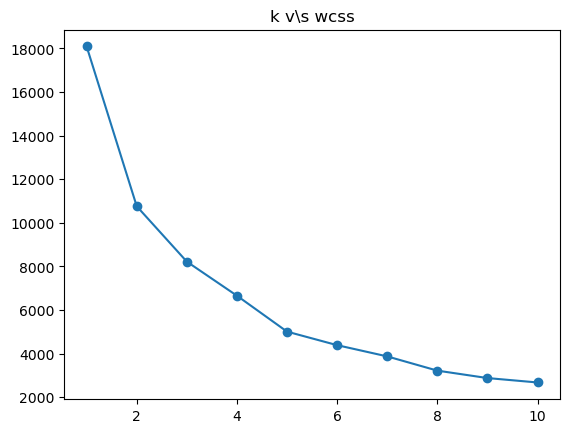

In [129]:
#plot k v\s wcss
plt.plot(range(1, 11), wcss, marker = 'o')
plt.title("k v\s wcss")

### 2.Silhouette Score

In [131]:
from sklearn.metrics import silhouette_score

scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters = k, random_state = 42)
    labels = kmeans.fit_predict(X_pca_3d)
    score = silhouette_score(X_pca_3d, labels)
    scores.append(score)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(
C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, 

Text(0.5, 1.0, 'k v\\s Silhouette Score')

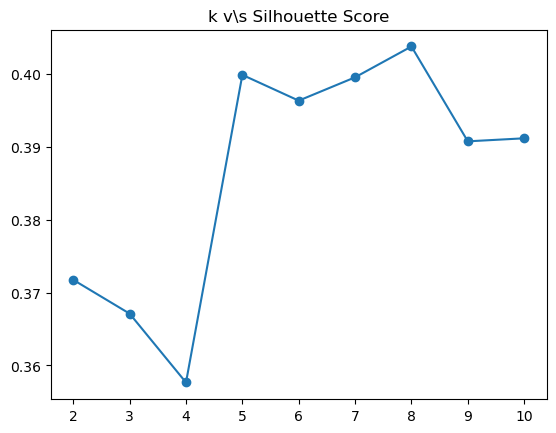

In [132]:
#plot k v\s Silhouette Score
plt.plot(range(2, 11), scores, marker = 'o')
plt.title("k v\s Silhouette Score")

#### by analyzing both graph, k = 4 is the best value

# Clustering

# KMeans

In [142]:
kmeans = KMeans(n_clusters = 4, random_state = 42)
labels_kmeans = kmeans.fit_predict(X_pca_3d)

C:\Users\HP\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=9.
  warnings.warn(


Text(0.5, 0.92, '3D Projection using Kmeans')

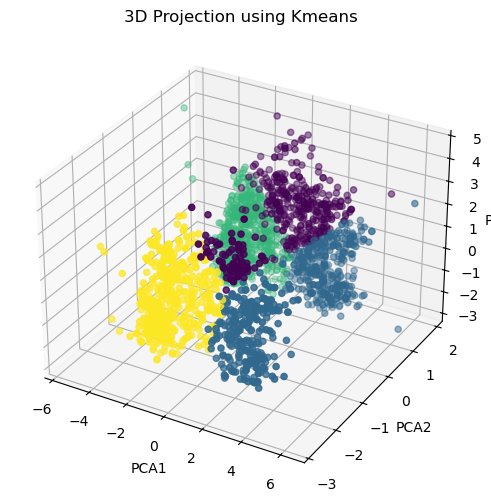

In [143]:
fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c = labels_kmeans)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D Projection using Kmeans")

## Hierarchical Clustering

In [144]:
from sklearn.cluster import AgglomerativeClustering

In [147]:
agg_clf = AgglomerativeClustering(n_clusters = 4)
labels_agg = agg_clf.fit_predict(X_pca_3d)

Text(0.5, 0.92, '3D Projection using Agglomerative Clustering')

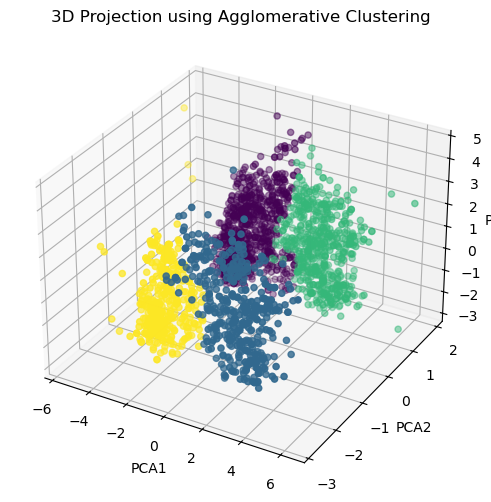

In [148]:
fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(111, projection = "3d")

ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c = labels_agg)

ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D Projection using Agglomerative Clustering")

### so here Agglomerative Clustering" creates proper cluster

# charaterization of Clusters

In [159]:
X["Clusters"] = labels_agg

In [161]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_tenure_date,Total_spending,Total_children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_with_Alone,Living_with_Partner,Living_with_nan,Clusters
0,58138.0,58,3,8,10,4,7,0,1,69,663,1617,0,1.0,0.0,0.0,1.0,0.0,0.0,1
1,46344.0,38,2,1,1,2,5,0,0,72,113,27,2,1.0,0.0,0.0,1.0,0.0,0.0,3
2,71613.0,26,1,8,2,10,4,0,0,61,312,776,0,1.0,0.0,0.0,0.0,1.0,0.0,2
3,26646.0,26,2,2,0,4,6,0,0,42,139,53,1,1.0,0.0,0.0,0.0,1.0,0.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,422,1,0.0,1.0,0.0,0.0,1.0,0.0,0


<Axes: xlabel='Clusters', ylabel='count'>

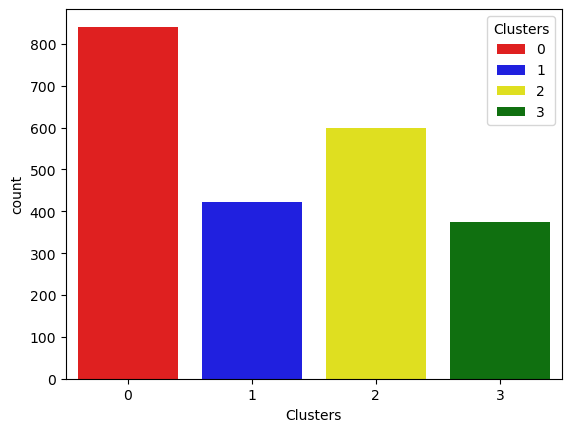

In [162]:
pal = ["red", "blue", "yellow", "green"]

sns.countplot(x = X["Clusters"], palette = pal, hue = X["Clusters"])

In [154]:
# Income and Spending pattern

<Axes: xlabel='Total_spending', ylabel='Income'>

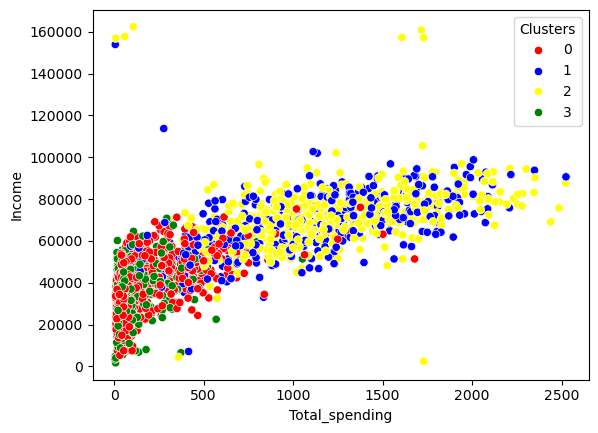

In [163]:
sns.scatterplot(x = X["Total_spending"], y = X["Income"], hue = X["Clusters"], palette = pal)

## Conclusion for Income v/s Total Spending based on Clusters

### Cluster 0: RED
    Income :- Low - Moderate
    Spending :- Moderate spending
    
### Cluster 1: BLUE
    Income :- Moderate - High
    Spending :- High

### Cluster 2: YELLOW
    Income :- High
    Spending :- High

### Cluster 3: GREEN
    Income :- Low
    Spending :- Low

In [165]:
#Cluster Summary
cluster_summary = X.groupby("Clusters").mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
Clusters                                                                
0         38257.804994  49.086801           2.569560         2.923900   
1         67279.986998  49.300236           2.245863         5.666667   
2         71263.914716  48.929766           2.061873         5.739130   
3         34534.693850  49.272727           2.291444         2.278075   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
Clusters                                                                        
0                    0.822830           3.873960           6.428062  0.008323   
1                    4.513002           7.992908           4.184397  0.004728   
2                    5.219064           8.555184           3.702341  0.010033   
3                    0.622995           3.219251           6.692513  0.013369   

          Response        Age  Customer_tenure_date  Total_spending  \
Clu

# Final Result

## Cluster 0
    - More Childrens
    - Living With partner
    - Poor Response
    - Web Activities are high
    - CatalogPurchases and StorePurchases are low

### Cluster 0 Peoples are basically family shoppers and price sensitive so here we can offer them discount coupons 

## Cluster 1
    - Fewer Childrens
    - Alone
    - Best Response
    - Web Activities are low
    - CatalogPurchases and StorePurchases are high
    - Slightly higher Age

### Cluster 2 Peoples High Value Singles so we can offer them premimum services or one to one services

## Cluster 2
    - Fewer Childrens
    - Living With partner
    - Avg. Response
    - Web Activities are low
    - CatalogPurchases and StorePurchases are high
    - Slightly higher Age

### Cluster 2 Peoples Premimum Customers so we can add them to loyalty program

## Cluster 3
    - More Childrens
    - Alone
    - Strong Response
    - Web Activities are high
    - CatalogPurchases and StorePurchases are low

### Cluster 1 Peoples are Digital Browsers, we can target them for sales or if there is heavy discount